# Online Retail — previsão de valor comprado em 30 dias
## 00 · Entendimento do negócio e dos dados | CRISP-DM

**Objetivo:** desenvolver um projeto de regressão, com decisões explicadas, evidências reproduzíveis e limites documentados.

Este notebook inicia o projeto; não treina um modelo. Seguimos as orientações das skills `ds-workbench`, `problem-framing` e `dataset-profiler` da biblioteca local `data-science-skills`.

**Como estudar:** execute as células em ordem, leia o motivo antes de cada análise e confronte a interpretação com a saída. As regras indicadas como provisórias serão revisadas com evidência, não tratadas como fatos do negócio.

| Etapa CRISP-DM | Entrega | Situação |
|---|---|---|
| 1. Entendimento do negócio | Objetivo, população, variável resposta, critérios | Proposta registrada aqui |
| 2. Entendimento dos dados | Leitura, qualidade, granularidade, viabilidade | Análise neste notebook |
| 3. Preparação | Regras finais, snapshots, features, divisão temporal | Próxima etapa |
| 4. Modelagem | Baselines, regressões e comparação controlada | Planejada |
| 5. Avaliação | Backtest temporal, erros e limitações | Planejada |
| 6. Implantação | Inferência em lote, model card e monitoramento proposto | Planejada |

O CRISP-DM é iterativo: uma descoberta pode exigir revisar a variável resposta ou a preparação. Implantação neste projeto não implica um sistema comercial em produção.

### Autoria e governança

Lucas Menghi desenvolve esta modelagem com assistência de agente de IA e aprovação humana no fluxo. O agente apoia a implementação, explica escolhas e executa verificações; Lucas define o escopo e revisa as decisões. Autorizações, hipóteses e aprovações pendentes são registradas em [Governança](docs/governance.md).

A continuidade dos experimentos e a publicação no repositório foram autorizadas. A definição final das regras e a promoção de modelos continuam sujeitas à revisão humana, sem alegação de aprovação produtiva.

## 1. Entendimento do negócio

**Cenário simulado:** uma equipe comercial quer estimar o valor de compras de clientes conhecidos para planejamento de receita e ordenação de uma carteira. Não temos um stakeholder real nem comprovação de impacto financeiro.

**Pergunta:** quanto cada cliente elegível comprará nos próximos 30 dias?

| Item | Contrato inicial |
|---|---|
| Unidade | Cliente × data de referência `t` |
| População | Cliente identificado com ao menos uma compra válida em `[t − 90 dias, t)` |
| Informação disponível | Somente eventos anteriores a `t` |
| Variável resposta | Soma de `Quantity × UnitPrice` de compras válidas em `[t, t + 30 dias)` |
| Ausência de recompra | Variável resposta igual a zero, desde que o horizonte esteja integralmente observado |
| Moeda | Libra esterlina (£), valores nominais históricos |
| Frequência proposta | Mensal; 30 dias não é sinônimo de mês-calendário |
| Compra válida provisória | Cliente, pedido, produto e data presentes; quantidade/preço positivos; sem prefixo de cancelamento |
| Fora do escopo | Novos clientes sem histórico, CLV vitalício, lucro, efeito causal de campanhas |

**Por que regressão?** O resultado é monetário e contínuo. Essa escolha atende ao objetivo de aprendizagem; sua utilidade será confrontada com regras simples.

**O que estamos prevendo:** valor bruto de transações positivas, sem deduzir devoluções. Isso não equivale a receita líquida contábil. Códigos de frete, taxas e ajustes ainda precisam ser investigados para decidir se integram o conceito de compra.

**Hipóteses a validar:** 90 dias contêm histórico suficiente; 30 dias têm eventos suficientes; o registro é contínuo; cada identificador representa consistentemente um cliente. Um cliente recém-observado pode ter histórico anterior ao início do arquivo.

### 1.1 Critérios de sucesso e escolha da função de perda

Neste projeto, sucesso é demonstrar uma comparação reproduzível, temporalmente válida e explicável — não inventar um limite de desempenho antes de observar os dados.

Como o uso proposto inclui **planejamento de receita**, queremos estimar o **valor esperado** de compras. Perda quadrática visa a média condicional; perda absoluta visa a mediana condicional. Com muitos zeros, uma boa mediana pode subestimar o total esperado.

Por isso refinamos a proposta anterior: **RMSE em £ será a referência principal inicial para seleção**, acompanhada obrigatoriamente de MAE em £, viés assinado e erro no total por período. Essa decisão será revisada se o objetivo passar a minimizar o erro típico por cliente. Nenhuma métrica isolada resolve os dois usos.

- **Baselines:** zero; gasto nos últimos 30 dias; gasto nos últimos 90 dias / 3. A referência zero revela o efeito da inatividade.
- **Modelos candidatos:** regressão regularizada com pré-processamento treinado apenas no treino; depois boosting. Tweedie ou modelo em duas etapas são alternativas condicionadas à distribuição observada.
- **Não usar MAPE como principal:** a variável resposta pode ser zero.
- **Não escolher automaticamente `log1p(y)`:** melhora a escala, mas otimiza outro problema; `expm1` da previsão não recupera automaticamente a média em £.
- **Sucesso preditivo:** superar baselines em períodos futuros, reportando estabilidade e erros por faixa de gasto. O ganho mínimo comercial está pendente.
- **Sucesso comercial:** não mensurável aqui. Não há custos, margens nem experimento de campanha; alta previsão não significa alto efeito de contato.

## 2. Entendimento dos dados

**Fonte declarada:** [UCI Online Retail](https://archive.ics.uci.edu/dataset/352/online+retail), Chen (2015), [DOI](https://doi.org/10.24432/C5BW33), licença CC BY 4.0. Atribuir a fonte na documentação.

A UCI descreve transações de uma loja britânica de presentes, com muitos atacadistas, entre 01/12/2010 e 09/12/2011. `InvoiceNo` iniciado em C indica cancelamento. Esses metadados orientam a auditoria, mas não substituem a verificação do arquivo.

**Arquivo analisado:** CSV local fornecido no projeto. Não verificamos equivalência byte a byte com o XLSX da UCI. O hash abaixo identifica exatamente a versão local.

### 2.1 Ambiente e leitura
O CSV usa `;`, vírgula decimal e datas dia/mês/ano. IDs são textos: usá-los como números confundiria identificadores com grandezas. Não instalamos dependências automaticamente dentro do notebook.

In [1]:
from pathlib import Path
from importlib.metadata import version
import hashlib
import platform
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Permite iniciar o kernel na pasta do notebook ou na pasta Python.
PROJECT_DIR = Path.cwd() if (Path.cwd() / 'src/retail.py').exists() else Path.cwd() / 'Online Retail'
sys.path.insert(0, str(PROJECT_DIR)) if str(PROJECT_DIR) not in sys.path else None
from src.retail import locate_data
DATA_PATH = locate_data(PROJECT_DIR)
if not DATA_PATH.is_file():
    raise FileNotFoundError("Abra a pasta Online Retail ou ajuste PROJECT_DIR para o diretório do CSV.")

LOOKBACK_DAYS = 90
HORIZON_DAYS = 30
# Reserva proposta, anterior à inspeção de distribuições da variável resposta.
TEST_REFERENCE = pd.Timestamp("2011-11-01")

print("Python:", platform.python_version())
# O caminho pessoal do interpretador não é publicado.
display(pd.Series({p: version(p) for p in ["pandas", "numpy", "matplotlib"]}, name="versão"))
raw_bytes = DATA_PATH.read_bytes()
print("SHA-256:", hashlib.sha256(raw_bytes).hexdigest())
try:
    raw_bytes.decode("utf-8-sig")
    encoding = "utf-8-sig"
except UnicodeDecodeError:
    encoding = "cp1252"  # Alternativa explícita para exportações Windows.
    raw_bytes.decode(encoding)  # Falhar se o fallback também for inválido.
del raw_bytes
print("Encoding utilizado:", encoding)

id_columns = ["InvoiceNo", "StockCode", "CustomerID", "Description", "Country"]
raw = pd.read_csv(DATA_PATH, sep=";", decimal=",", encoding=encoding,
                  dtype={col: "string" for col in id_columns})
expected = set(id_columns + ["Quantity", "InvoiceDate", "UnitPrice"])
assert set(raw.columns) == expected, f"Schema inesperado: {raw.columns.tolist()}"
assert len(raw) > 0, "Arquivo vazio"
df = raw.copy()
for col in id_columns:
    df[col] = df[col].str.strip().replace("", pd.NA)
df["InvoiceDate"] = pd.to_datetime(raw["InvoiceDate"], format="%d/%m/%Y %H:%M", errors="coerce")
for col in ["Quantity", "UnitPrice"]:
    df[col] = pd.to_numeric(raw[col], errors="coerce")
display(df.head())
print(f"Linhas: {len(df):,}; colunas: {df.shape[1]}")

Python: 3.11.7


pandas         2.1.4
numpy         1.26.4
matplotlib     3.8.0
Name: versão, dtype: object

SHA-256: 7f64af8f3f2e1260f4a97c40ff1c95c8bed3dfeefdacc0367592e68b6a971564
Encoding utilizado: utf-8-sig


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


Linhas: 541,909; colunas: 8


### 2.2 Qualidade e granularidade

Uma linha é um item registrado em um pedido; não é um cliente nem necessariamente um pedido inteiro. A frequência de compras deve contar pedidos distintos.

Medimos nulos, conversões inválidas e duplicatas antes de excluir qualquer linha. Linhas idênticas podem ser duplicação técnica ou eventos legítimos sem identificador suficiente: não apagamos automaticamente. Anomalias podem se sobrepor, então suas contagens não devem ser somadas como exclusões independentes.

In [2]:
profile = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "nulos_n": df.isna().sum(),
    "nulos_pct": df.isna().mean().mul(100),
    "distintos": df.nunique(dropna=True),
})
display(profile)
parse_failures = {col: int((raw[col].notna() & df[col].isna()).sum())
                  for col in ["InvoiceDate", "Quantity", "UnitPrice"]}
display(pd.Series(parse_failures, name="falhas_conversão"))
assert not any(parse_failures.values()), "Resolver falhas de conversão antes de continuar."

cancelled = df["InvoiceNo"].str.upper().str.startswith("C", na=False)
flags = pd.DataFrame({
    "sem_cliente": df["CustomerID"].isna(),
    "cancelamento": cancelled,
    "quantidade_nao_positiva": df["Quantity"].le(0),
    "preco_nao_positivo": df["UnitPrice"].le(0),
    "duplicata_excedente": df.duplicated(),
    "sem_descricao": df["Description"].isna(),
})
display(pd.DataFrame({"linhas": flags.sum(), "%_do_arquivo": flags.mean() * 100}))
print("Datas:", df["InvoiceDate"].min(), "até", df["InvoiceDate"].max())
print("Clientes identificados:", df["CustomerID"].nunique())
print("Pedidos distintos:", df["InvoiceNo"].nunique())
print("Repetições excedentes de pedido/produto:", df.duplicated(["InvoiceNo", "StockCode"]).sum())
invoice_customers = df.groupby("InvoiceNo")["CustomerID"].nunique()
print("Pedidos associados a mais de um cliente:", invoice_customers.gt(1).sum())
display(df[["Quantity", "UnitPrice"]].describe(percentiles=[.01, .5, .9, .99]).T)

,tipo,nulos_n,nulos_pct,distintos
InvoiceNo,string,0,0.00,25900
StockCode,string,0,0.00,4070
Description,string,1454,0.27,4211
Quantity,int64,0,0.00,722
InvoiceDate,datetime64[ns],0,0.00,23260
UnitPrice,float64,0,0.00,1630
CustomerID,string,135080,24.93,4372
Country,string,0,0.00,38


InvoiceDate    0
Quantity       0
UnitPrice      0
Name: falhas_conversão, dtype: int64

,linhas,%_do_arquivo
sem_cliente,135080,24.93
cancelamento,9288,1.71
quantidade_nao_positiva,10624,1.96
preco_nao_positivo,2517,0.46
duplicata_excedente,5268,0.97
sem_descricao,1454,0.27


Datas: 2010-12-01 08:26:00 até 2011-12-09 12:50:00
Clientes identificados: 4372
Pedidos distintos: 25900
Repetições excedentes de pedido/produto: 10684


Pedidos associados a mais de um cliente: 0


,count,mean,std,min,1%,50%,90%,99%,max
Quantity,"541,909.00",9.55,218.08,"-80,995.00",-2.00,3.00,24.00,100.00,"80,995.00"
UnitPrice,"541,909.00",4.61,96.76,"-11,062.06",0.19,2.08,7.95,18.00,"38,970.00"


### 2.3 Cobertura temporal e reserva de avaliação

A auditoria de schema e cobertura considera o arquivo inteiro. As distribuições comportamentais e a variável resposta exploratório abaixo usam somente o período anterior à referência reservada de teste (01/11/2011). Não usamos seus resultados futuros para escolher features ou modelos.

O último dia pode estar incompleto. Adotamos provisoriamente seu início como limite exclusivo de acompanhamento. Isso é conservador, mas não comprova ausência de lacunas na fonte. Ausência de transações em um dia também não prova falha de coleta.

O teste proposto será curto e sazonal; um único período não comprova generalização. Backtests anteriores devem complementar sua avaliação.

In [3]:
coverage = df.assign(month=df["InvoiceDate"].dt.to_period("M")).groupby("month").agg(
    linhas=("InvoiceNo", "size"), pedidos=("InvoiceNo", "nunique"),
    clientes=("CustomerID", "nunique"), inicio=("InvoiceDate", "min"), fim=("InvoiceDate", "max"))
display(coverage)
DATA_START = df["InvoiceDate"].min().normalize()
OBSERVED_END_EXCLUSIVE = df["InvoiceDate"].max().normalize()
assert TEST_REFERENCE + pd.Timedelta(days=HORIZON_DAYS) <= OBSERVED_END_EXCLUSIVE
dev = df.loc[df["InvoiceDate"] < TEST_REFERENCE].copy()
print("Fim exclusivo conservador de acompanhamento:", OBSERVED_END_EXCLUSIVE)
print("Linhas disponíveis para discovery comportamental:", len(dev))

,linhas,pedidos,clientes,inicio,fim
month,,,,,
2010-12,42481,2025,948,2010-12-01 08:26:00,2010-12-23 17:41:00
2011-01,35147,1476,783,2011-01-04 10:00:00,2011-01-31 16:59:00
2011-02,27707,1393,798,2011-02-01 08:23:00,2011-02-28 17:04:00
2011-03,36748,1983,1020,2011-03-01 08:30:00,2011-03-31 19:55:00
2011-04,29916,1744,899,2011-04-01 08:22:00,2011-04-28 19:53:00
2011-05,37030,2162,1079,2011-05-01 10:51:00,2011-05-31 15:53:00
2011-06,36874,2012,1051,2011-06-01 07:37:00,2011-06-30 20:08:00
2011-07,39518,1927,993,2011-07-01 08:16:00,2011-07-31 16:04:00
2011-08,35284,1737,980,2011-08-01 08:30:00,2011-08-31 17:45:00


Fim exclusivo conservador de acompanhamento: 2011-12-09 00:00:00
Linhas disponíveis para discovery comportamental: 431673


### 2.4 Elegibilidade provisória e investigação de extremos

Construímos uma visão de compras candidatas sem alterar o CSV. As exclusões abaixo são sequenciais e reconciliáveis. Clientes anônimos ficam fora do modelo individual; registrar essa perda é necessário para não apresentar a soma das previsões como receita total da loja.

Mantemos valores altos e duplicatas por enquanto. Atacadistas podem explicar parte da cauda. Remover extremos por um percentil arbitrário mudaria justamente o público de maior valor; primeiro investigamos sua natureza.

In [4]:
criteria = {
    "campos_essenciais_presentes": dev[["CustomerID", "InvoiceNo", "StockCode", "InvoiceDate", "Quantity", "UnitPrice"]].notna().all(axis=1),
    "sem_cancelamento": ~dev["InvoiceNo"].str.upper().str.startswith("C", na=False),
    "quantidade_positiva": dev["Quantity"].gt(0),
    "preco_positivo": dev["UnitPrice"].gt(0),
}
keep = pd.Series(True, index=dev.index)
funnel = []
for rule, passes in criteria.items():
    before = int(keep.sum())
    keep &= passes
    funnel.append({"regra": rule, "excluidas_nesta_etapa": before - int(keep.sum()), "restantes": int(keep.sum())})
display(pd.DataFrame(funnel))
sales = dev.loc[keep].copy()
sales["line_value_gbp"] = sales["Quantity"] * sales["UnitPrice"]
assert np.isfinite(sales["line_value_gbp"]).all()
assert (sales["line_value_gbp"] > 0).all()
assert len(dev) == len(sales) + sum(row["excluidas_nesta_etapa"] for row in funnel)

display(sales.nlargest(10, "line_value_gbp")[["InvoiceDate", "StockCode", "Description", "Quantity", "UnitPrice", "line_value_gbp"]])
display(sales.groupby("Country").agg(linhas=("InvoiceNo", "size"), clientes=("CustomerID", "nunique"), valor_gbp=("line_value_gbp", "sum")).sort_values("valor_gbp", ascending=False).head(10))
# Códigos fora do padrão usual são candidatos a revisão, não erros comprovados.
unusual_code = ~sales["StockCode"].str.fullmatch(r"\d{5}[A-Za-z]*", na=False)
display(sales.loc[unusual_code].groupby(["StockCode", "Description"], dropna=False).agg(
    linhas=("InvoiceNo", "size"), valor_gbp=("line_value_gbp", "sum")).sort_values("valor_gbp", ascending=False).head(20))

,regra,excluidas_nesta_etapa,restantes
0,campos_essenciais_presentes,108103,323570
1,sem_cancelamento,7495,316075
2,quantidade_positiva,0,316075
3,preco_positivo,26,316049


,InvoiceDate,StockCode,Description,Quantity,UnitPrice,line_value_gbp
61619,2011-01-18 10:01:00,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,"77,183.60"
222680,2011-06-10 15:28:00,22502,PICNIC BASKET WICKER 60 PIECES,60,649.50,"38,970.00"
173382,2011-05-03 13:46:00,POST,POSTAGE,1,"8,142.75","8,142.75"
348325,2011-09-20 11:05:00,23243,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,5.06,"7,144.72"
52711,2011-01-11 12:55:00,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,"6,539.40"
160546,2011-04-18 13:20:00,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,"6,539.40"
421601,2011-10-27 12:11:00,23084,RABBIT NIGHT LIGHT,2400,2.08,"4,992.00"
52709,2011-01-11 12:55:00,85123A,WHITE HANGING HEART T-LIGHT HOLDER,1930,2.55,"4,921.50"
160542,2011-04-18 13:20:00,85123A,WHITE HANGING HEART T-LIGHT HOLDER,1930,2.40,"4,632.00"
52772,2011-01-11 12:57:00,48185,DOORMAT FAIRY CAKE,670,6.75,"4,522.50"


,linhas,clientes,valor_gbp
Country,,,
United Kingdom,279720,3589,"5,855,361.63"
Netherlands,2048,9,"247,844.31"
EIRE,5907,3,"229,093.57"
Germany,7629,87,"192,857.95"
France,6522,80,"170,410.04"
Australia,1141,9,"131,278.59"
Spain,2115,26,"52,581.94"
Switzerland,1616,19,"48,324.99"
Sweden,374,7,"35,418.10"


,,linhas,valor_gbp
StockCode,Description,,
POST,POSTAGE,888,"64,694.01"
M,Manual,236,"50,355.51"
C2,CARRIAGE,108,"5,436.00"
DOT,DOTCOM POSTAGE,11,"5,101.76"
BANK CHARGES,Bank Charges,9,120.00
PADS,PADS TO MATCH ALL CUSHIONS,3,0.00


### 2.5 Experimento de viabilidade da variável resposta (desenvolvimento)

Esta é uma construção exploratória, não a tabela final de treino. Usamos referências mensais com 90 dias de histórico disponíveis e 30 dias futuros completos, encerrados antes do teste reservado.

O conjunto de clientes vem **do passado**. Depois associamos as compras futuras e preenchemos zero somente para clientes elegíveis sem eventos no horizonte completo. Selecionar apenas quem comprou no futuro eliminaria os zeros e mudaria a pergunta do modelo.

Clientes podem aparecer em várias referências; isso não gera observações independentes. Não faremos split aleatório por linha. Janelas futuras mensais também podem se sobrepor, exigindo atenção nos folds temporais.

In [5]:
first_reference = (DATA_START + pd.Timedelta(days=LOOKBACK_DAYS)).ceil("D")
references = pd.date_range(first_reference, TEST_REFERENCE, freq="MS")
references = [t for t in references if t + pd.Timedelta(days=HORIZON_DAYS) <= TEST_REFERENCE]
snapshots = []
for t in references:
    past = sales.loc[sales["InvoiceDate"].ge(t - pd.Timedelta(days=LOOKBACK_DAYS)) & sales["InvoiceDate"].lt(t)]
    future = sales.loc[sales["InvoiceDate"].ge(t) & sales["InvoiceDate"].lt(t + pd.Timedelta(days=HORIZON_DAYS))]
    eligible = pd.Index(past["CustomerID"].unique(), name="CustomerID")
    target = future.groupby("CustomerID")["line_value_gbp"].sum().reindex(eligible, fill_value=0)
    snapshot = target.rename("target_gbp_30d").reset_index()
    snapshot["reference_date"] = t
    assert snapshot["CustomerID"].is_unique
    assert snapshot["target_gbp_30d"].ge(0).all()
    expected_total = future.loc[future["CustomerID"].isin(eligible), "line_value_gbp"].sum()
    assert np.isclose(snapshot["target_gbp_30d"].sum(), expected_total)
    snapshots.append(snapshot)
assert snapshots, "Não há referências com histórico e horizonte suficientes."
target_preview = pd.concat(snapshots, ignore_index=True)
assert not target_preview.duplicated(["CustomerID", "reference_date"]).any()
target_summary = target_preview.groupby("reference_date")["target_gbp_30d"].agg(
    clientes="size", zeros_pct=lambda s: s.eq(0).mean() * 100,
    media_gbp="mean", mediana_gbp="median", p90_gbp=lambda s: s.quantile(.9),
    p99_gbp=lambda s: s.quantile(.99), max_gbp="max", total_gbp="sum")
display(target_summary)
print("Cliente × referência:", len(target_preview))
print("Clientes únicos no conjunto exploratório:", target_preview["CustomerID"].nunique())
print("Duplicatas exatas excedentes mantidas nas compras candidatas:", sales.duplicated(subset=df.columns.tolist()).sum())

,clientes,zeros_pct,media_gbp,mediana_gbp,p90_gbp,p99_gbp,max_gbp,total_gbp
reference_date,,,,,,,,
2011-03-01,1682,70.10,224.79,0.00,514.25,"2,919.35","21,462.40","378,093.08"
2011-04-01,1776,72.13,181.84,0.00,454.26,"2,943.42","21,535.90","322,954.38"
2011-05-01,1891,64.57,267.69,0.00,632.20,"3,168.95","28,408.14","506,201.21"
2011-06-01,1959,67.59,239.10,0.00,510.96,"2,427.16","41,959.44","468,389.74"
2011-07-01,1969,68.66,221.56,0.00,555.19,"2,841.78","22,949.76","436,258.76"
2011-08-01,2025,68.25,247.29,0.00,569.13,"2,879.20","40,327.81","500,755.69"
2011-09-01,1923,62.14,354.27,0.00,691.91,"3,673.55","75,412.64","681,269.11"
2011-10-01,2151,64.76,329.65,0.00,670.63,"4,515.81","52,681.27","709,079.08"


Cliente × referência: 15376
Clientes únicos no conjunto exploratório: 3616


Duplicatas exatas excedentes mantidas nas compras candidatas: 3551


### 2.6 Visualização da variável resposta

Zeros medem ausência de recompra no horizonte; a cauda mostra a concentração dos valores positivos. A escala logarítmica abaixo serve apenas à visualização, sem decidir transformação da variável resposta do modelo. Os totais de referências sobrepostas não devem ser somados como faturamento do período.

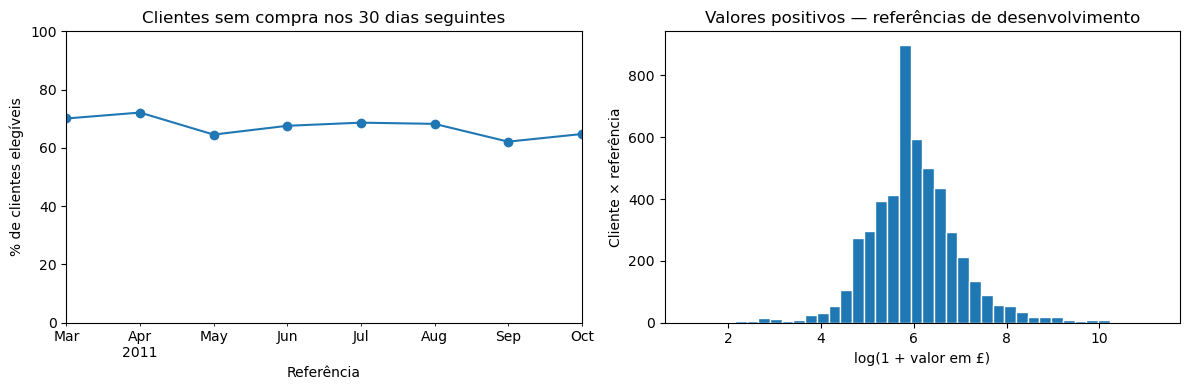

No desenvolvimento, a proporção de zeros varia de 62.1% a 72.1% por referência.
Interpretação: comparar sempre com previsões simples e separar erros em clientes com e sem compra.
Valores extremos e natureza de códigos especiais ainda precisam de revisão antes de congelar a variável resposta.


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
target_summary["zeros_pct"].plot(marker="o", ax=axes[0])
axes[0].set(title="Clientes sem compra nos 30 dias seguintes", ylabel="% de clientes elegíveis", xlabel="Referência")
axes[0].set_ylim(0, 100)
positive = target_preview.loc[target_preview["target_gbp_30d"] > 0, "target_gbp_30d"]
axes[1].hist(np.log1p(positive), bins=40, edgecolor="white")
axes[1].set(title="Valores positivos — referências de desenvolvimento", xlabel="log(1 + valor em £)", ylabel="Cliente × referência")
plt.tight_layout()
plt.show()

print(f"No desenvolvimento, a proporção de zeros varia de {target_summary.zeros_pct.min():.1f}% a {target_summary.zeros_pct.max():.1f}% por referência.")
print("Interpretação: comparar sempre com previsões simples e separar erros em clientes com e sem compra.")
print("Valores extremos e natureza de códigos especiais ainda precisam de revisão antes de congelar a variável resposta.")

## 3. Registro de decisões e pendências

| Decisão | Motivo / alternativa | Estado e evidência que pode mudar a escolha |
|---|---|---|
| Regressão de valor em 30 dias | Resultado monetário alinhado ao objetivo de aprendizagem | Confirmado pelo usuário; população ainda provisória |
| Histórico de 90 dias | Limita informação ao passado e permite referências no período disponível | Provisório; avaliar cobertura e estabilidade |
| Bruto de compras positivas | Regra reproduzível, sem atribuição retroativa de devoluções | Provisório; reconciliar códigos especiais e devoluções |
| Clientes identificados | Sem ID não há trajetória individual confiável | Medir cobertura; nunca generalizar à receita inteira da loja |
| Preservar zeros | Ausência de compra faz parte do problema | Manter somente com acompanhamento completo |
| Preservar duplicatas/extremos na descoberta | Não há evidência suficiente para remoção automática | Investigar e comparar sensibilidade das regras no desenvolvimento |
| RMSE + MAE + viés temporal | Distingue valor esperado, erro típico e planejamento agregado | Reavaliar conforme objetivo final e concentração de valores |
| Teste proposto em novembro/2011 | Avaliação posterior ao desenvolvimento | Reservado; curto, sazonal e sem avaliação de desempenho nesta etapa |

### Próxima etapa: fechar a preparação antes de treinar

1. Revisar os códigos especiais, as duplicatas e os maiores valores; registrar regras e impacto em linhas, clientes e £.
2. Confirmar se a variável resposta deve incluir frete/taxas e como interpretar cancelamentos. A fonte não fornece aprovação dessas regras.
3. Construir features com recência, pedidos distintos, gasto e diversidade nas janelas de 30/60/90 dias. Não usar `CustomerID` como variável numérica explicativa.
4. Definir folds de backtest garantindo `fim_da_resposta_treino <= início_da_validação`; transformações são ajustadas somente no treino. O mesmo cliente pode aparecer em períodos diferentes porque o caso de uso é prever clientes existentes.
5. Congelar o teste e só então comparar baselines e modelos. Se o teste orientar mudanças, registrar seu uso e não chamá-lo de intocado.

**Limitações:** dados históricos de uma loja, curto período, comportamento atacadista, cobertura incompleta de clientes, regras comerciais simuladas e ausência de medidas de campanha. Nenhuma conclusão causal ou de prontidão produtiva é autorizada por este notebook.

**Aprendizado para discutir:** observe a distância entre média e mediana da variável resposta. Qual delas responde melhor à soma de receita esperada? Essa diferença é o motivo para explicitar a função de perda antes de escolher o algoritmo.

### Referências e rastreabilidade
- Chen, D. (2015). Online Retail. UCI Machine Learning Repository. https://doi.org/10.24432/C5BW33 — CC BY 4.0.
- CRISP-DM: entendimento do negócio, entendimento dos dados, preparação, modelagem, avaliação e implantação.
- Orientação local: `data-science-skills/13-ai-assistants/ds-workbench/SKILL.md`, `01-business-understanding/problem-framing/SKILL.md`, `02-data-discovery/dataset-profiler/SKILL.md` e `guides/decision-protocol.md`.
- Versões do ambiente e hash do arquivo estão nas saídas; resultados se referem ao CSV local e às regras provisórias documentadas.